# 1.0 Method #

In [1]:
import numpy as np
import pandas as pd
import time
from codecarbon import EmissionsTracker, OfflineEmissionsTracker
import re
from transformers import BertModel, BertTokenizer
import torch
from scipy.stats import skew
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.cluster import AgglomerativeClustering
from tabulate import tabulate
import matplotlib.pyplot as plt

[codecarbon WARNING @ 19:20:34] Nvidia GPU detected but pynvml initialization failed. Please ensure NVIDIA drivers are properly installed.


In [2]:
TEXT_COL = "sentence"
LABEL_COL = "label"

SAMPLE_SIZE = 200
RANDOM_SEED = 42
BATCH_SIZE = 64
MAX_TOKEN = 128

MODELS = [
    "google-bert/bert-base-uncased",
    "allenai/scibert_scivocab_uncased",
    "nlpaueb/legal-bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "Lianglab/PharmBERT-uncased",
    "recobo/agriculture-bert-uncased",
    "recobo/chemical-bert-uncased"
]

### 1.1 Negative Correlation Based Asymmetry Testing

In [3]:
def asymmetry_eta(x, bandwidth=None):
    """
    Estimate eta using Patil et al.-style estimator:
    eta_hat = -Corr(f_hat(X_i), F_hat(X_i))

    f_hat(X_i): leave-one-out Gaussian KDE
    F_hat(X_i): leave-one-out empirical CDF
    """
    x = np.asarray(x, dtype=float)
    x = x[~np.isnan(x)]
    n = len(x)

    if n < 3:
        return np.nan

    # Silverman's bandwidth
    s = np.std(x, ddof=1)
    iqr = np.subtract(*np.percentile(x, [75, 25]))
    sigma = min(s, iqr / 1.349) if iqr > 0 else s
    if np.isclose(sigma, 0):
        sigma = s if s > 0 else 1.0
    h = bandwidth if bandwidth is not None else 0.9 * sigma * (n ** (-1 / 5))#calculate bandwidth
    if h <= 0:
        h = 1.06 * (s if s > 0 else 1.0) * (n ** (-1 / 5))

    # Leave-one-out KDE
    diffs = (x[None, :] - x[:, None]) / h#cal culate pairwise difference
    K = stats.norm.pdf(diffs)#fit standardized distance into gaussian kernel
    np.fill_diagonal(K, 0.0)#leave one out
    f_hat = K.sum(axis=1) / ((n - 1) * h)#KED for pdf

    # Leave-one-out empirical CDF
    indicators = (x[None, :] < x[:, None]).astype(float)
    np.fill_diagonal(indicators, 0.0)
    F_hat = indicators.sum(axis=1) / (n - 1)

    if np.std(f_hat, ddof=1) == 0 or np.std(F_hat, ddof=1) == 0:
        return np.nan

    eta = -np.corrcoef(f_hat, F_hat)[0, 1]#calculate correlation

    return eta

### 1.2 Distribution distance based differentiation testing

### 1.2 All pairwise cosine similarity

In [4]:
def calculate_pairwise_cosine_distribution(embeddings):
    scores = []

    for i in range(len(embeddings)):
        for j in range(i + 1, len(embeddings)):
            sim = torch.nn.functional.cosine_similarity(
                embeddings[i],
                embeddings[j],
                dim=0
            )
            scores.append(sim.item())

    return np.array(scores)

### 1.3 Pairwise Cosine simimarity (same label pairs)

In [15]:
def calculate_within_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label=True
):

    labels = np.asarray(labels)
    unique_labels = np.unique(labels)

    all_scores = []#saving all results from different labels
    scores_by_label = {}#dictionary, saving results for each label

    for lab in unique_labels:
        idx = np.where(labels == lab)[0]

        # Need at least 2 samples to calculate pairwise cosine
        if len(idx) < 2:
            print(f"Label {lab}: skipped, only {len(idx)} sample")
            continue

        scores = []

        # Calculate cosine similarity only inside the same label
        for a in range(len(idx)):
            for b in range(a + 1, len(idx)):
                i = idx[a]
                j = idx[b]

                sim = torch.nn.functional.cosine_similarity(
                    embeddings[i],
                    embeddings[j],
                    dim=0
                )

                scores.append(sim.item())

        scores = np.array(scores)

        scores_by_label[lab] = scores
        all_scores.extend(scores)

        print(f"Label {lab}: {len(idx)} samples, {len(scores)} pairs")

    all_scores = np.array(all_scores)

    if return_by_label:
        return all_scores, scores_by_label
    else:
        return all_scores

### 1.4 Pairwise Cosine Similarity (Same and Different label)

In [16]:
def calculate_between_label_cosine_distribution(
    embeddings,
    labels,
    return_by_label_pair=True
):
    labels = np.asarray(labels)
    
    all_scores = []
    scores_by_label_pair = {}

    n = len(labels)

    for i in range(n):
        for j in range(i + 1, n):

            # only calculate pairs from different labels
            if labels[i] == labels[j]:
                continue

            lab_i = labels[i]
            lab_j = labels[j]

            sim = torch.nn.functional.cosine_similarity(
                embeddings[i],
                embeddings[j],
                dim=0
            )

            score = sim.item()
            all_scores.append(score)

            # make label pair order fixed, e.g. (0, 2), not sometimes (2, 0)
            label_pair = tuple(sorted((lab_i, lab_j)))

            if label_pair not in scores_by_label_pair:
                scores_by_label_pair[label_pair] = []

            scores_by_label_pair[label_pair].append(score)

    # convert to numpy arrays
    all_scores = np.array(all_scores)

    for pair in scores_by_label_pair:
        scores_by_label_pair[pair] = np.array(scores_by_label_pair[pair])

    print("Total between-label pairs:", len(all_scores))

    for pair, scores in scores_by_label_pair.items():
        print(f"Label {pair[0]} vs Label {pair[1]}: {len(scores)} pairs")

    if return_by_label_pair:
        return all_scores, scores_by_label_pair
    else:
        return all_scores

## 2.0 Dataset

In [3]:
csv = "financial_original.csv"
df = pd.read_csv(csv)
print(df.head())
print(df.columns)
print(df.shape)

                                            sentence  label
0  According to Gran , the company has no plans t...      1
1  Technopolis plans to develop in stages an area...      1
2  The international electronic industry company ...      0
3  With the new production plant the company woul...      2
4  According to the company 's updated strategy f...      2
Index(['sentence', 'label'], dtype='str')
(4846, 2)


In [4]:
def clean_text(text):
    text = str(text)
    text = re.sub(r"[?|!|\'|\"|#]", "", text)
    text = re.sub(r"[.|,|)|(|\\|/]", " ", text)
    text = text.replace("\n", " ")
    text = re.sub(r"\s+", " ", text)
    return text.strip()


def load_and_clean_dataset(csv_file):
    df = pd.read_csv(csv_file)
    df = df[[TEXT_COL, LABEL_COL]].dropna().drop_duplicates().copy()

    df["clean_sentence"] = df[TEXT_COL].apply(clean_text)
    df["length"] = df["clean_sentence"].apply(len)

    print(df.head())
    print(df[LABEL_COL].value_counts())
    print(df.shape)

    return df

In [5]:
def add_length_quantile_groups(df, num_quantiles=100):
    df = df.copy()

    quantiles = df["length"].quantile(
        [i / num_quantiles for i in range(1, num_quantiles)]
    ).tolist()

    quantiles = np.unique(quantiles).tolist()

    bins = [df["length"].min()] + quantiles + [df["length"].max()]
    labels = [f"Q{i+1}" for i in range(len(bins) - 1)]

    df["quantiles"] = pd.cut(
        df["length"],
        bins=bins,
        labels=labels,
        include_lowest=True,
        duplicates="drop"
    )

    print(df["quantiles"].value_counts().sort_index())

    return df

In [6]:
df = load_and_clean_dataset(csv)

                                            sentence  label  \
0  According to Gran , the company has no plans t...      1   
1  Technopolis plans to develop in stages an area...      1   
2  The international electronic industry company ...      0   
3  With the new production plant the company woul...      2   
4  According to the company 's updated strategy f...      2   

                                      clean_sentence  length  
0  According to Gran the company has no plans to ...     121  
1  Technopolis plans to develop in stages an area...     186  
2  The international electronic industry company ...     224  
3  With the new production plant the company woul...     204  
4  According to the company s updated strategy fo...     198  
label
1    2873
2    1363
0     604
Name: count, dtype: int64
(4840, 4)


In [7]:
df = add_length_quantile_groups(df)
print(df.head())
print(df.columns)
print(df.shape)

quantiles
Q1      51
Q2      46
Q3      55
Q4      43
Q5      47
        ..
Q96     41
Q97     49
Q98     50
Q99     48
Q100    46
Name: count, Length: 100, dtype: int64
                                            sentence  label  \
0  According to Gran , the company has no plans t...      1   
1  Technopolis plans to develop in stages an area...      1   
2  The international electronic industry company ...      0   
3  With the new production plant the company woul...      2   
4  According to the company 's updated strategy f...      2   

                                      clean_sentence  length quantiles  
0  According to Gran the company has no plans to ...     121       Q54  
1  Technopolis plans to develop in stages an area...     186       Q86  
2  The international electronic industry company ...     224       Q95  
3  With the new production plant the company woul...     204       Q91  
4  According to the company s updated strategy fo...     198       Q89  
Index(['sente

## 3.0 Data Sampling

In [8]:
def sample_from_length_groups(df, sample_size=200, num_quantiles=100, random_seed=42):
    n_samples = sample_size // num_quantiles

    sampled_df = (
        df.groupby("quantiles", group_keys=False)
        .apply(lambda x: x.sample(n=min(n_samples, len(x)), random_state=random_seed))
        .reset_index(drop=True)
    )

    print("Actual Sample Size:", len(sampled_df))
    print("Minimum Token Count:", sampled_df["clean_sentence"].str.split().apply(len).min())
    print("Average Token Count:", sampled_df["clean_sentence"].str.split().apply(len).mean())
    print("Maximum Token Count:", sampled_df["clean_sentence"].str.split().apply(len).max())

    return sampled_df

## 3.0 Embedding

In [9]:
def compute_embeddings(texts, model_name, batch_size=64, max_token=128):
    tokenizer = BertTokenizer.from_pretrained(model_name)
    model = BertModel.from_pretrained(model_name)

    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = model.to(device)
    model.eval()

    embeddings = []

    for i in range(0, len(texts), batch_size):
        batch_texts = texts[i:i + batch_size]

        inputs = tokenizer(
            batch_texts,
            return_tensors="pt",
            padding=True,
            truncation=True,
            max_length=max_token
        )

        inputs = {k: v.to(device) for k, v in inputs.items()}

        with torch.no_grad():
            outputs = model(**inputs)
            batch_embeddings = outputs.last_hidden_state.mean(dim=1).cpu()

        embeddings.append(batch_embeddings)

    return torch.cat(embeddings)

## 4.0 Requared Diagram

Actual Sample Size: 200
Minimum Token Count: 5
Average Token Count: 21.645
Maximum Token Count: 49
Sample size used for cosine similarity: 200

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Number of pairwise cosine scores: 19900
Mean cosine similarity: 0.6895021
Std cosine similarity: 0.07271937
Skewness: 0.011588494

Running model: ahmedrachid/FinancialBERT


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: ahmedrachid/FinancialBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstr

Number of pairwise cosine scores: 19900
Mean cosine similarity: 0.7400139
Std cosine similarity: 0.06825642
Skewness: -0.7457715

Running model: recobo/agriculture-bert-uncased


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/agriculture-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your d

Number of pairwise cosine scores: 19900
Mean cosine similarity: 0.8258525
Std cosine similarity: 0.043388925
Skewness: -0.4703383


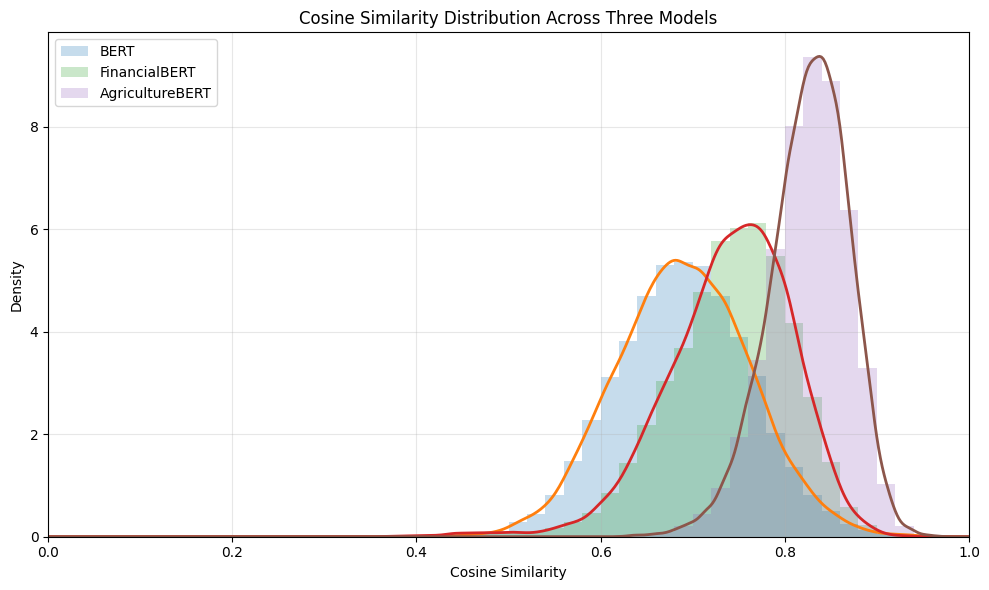

In [13]:
# ==============================
# Cosine Similarity Distribution Plot
# Compare 3 selected models
# ==============================

import gc
from scipy.stats import gaussian_kde

# 1. Select three models for visualization
SELECTED_MODELS = [
    "google-bert/bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "recobo/agriculture-bert-uncased"
]

# 2. Sample data from the cleaned dataset
sampled_df = sample_from_length_groups(
    df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    random_seed=RANDOM_SEED
)

texts = sampled_df["clean_sentence"].tolist()

print("Sample size used for cosine similarity:", len(texts))

MODEL_DISPLAY_NAMES = {
    "google-bert/bert-base-uncased": "BERT",
    "ahmedrachid/FinancialBERT": "FinancialBERT",
    "recobo/agriculture-bert-uncased": "AgricultureBERT"
}
# 3. Faster pairwise cosine similarity calculation
def calculate_pairwise_cosine_distribution_fast(embeddings):
    """
    Calculate all pairwise cosine similarities from embedding matrix.
    This version is faster than the double for-loop version.
    """
    embeddings = torch.nn.functional.normalize(embeddings, p=2, dim=1)

    sim_matrix = torch.matmul(embeddings, embeddings.T)

    upper_triangle_indices = torch.triu_indices(
        sim_matrix.size(0),
        sim_matrix.size(1),
        offset=1
    )

    scores = sim_matrix[
        upper_triangle_indices[0],
        upper_triangle_indices[1]
    ]

    return scores.cpu().numpy()


# 4. Compute cosine similarity distributions
cosine_results = {}

for model_name in SELECTED_MODELS:
    print(f"\nRunning model: {model_name}")

    embeddings = compute_embeddings(
        texts,
        model_name=model_name,
        batch_size=BATCH_SIZE,
        max_token=MAX_TOKEN
    )

    cosine_scores = calculate_pairwise_cosine_distribution_fast(embeddings)

    cosine_results[model_name] = cosine_scores

    print("Number of pairwise cosine scores:", len(cosine_scores))
    print("Mean cosine similarity:", np.mean(cosine_scores))
    print("Std cosine similarity:", np.std(cosine_scores))
    print("Skewness:", skew(cosine_scores))

    # clean GPU / RAM after each model
    del embeddings
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# 5. Plot three cosine similarity distributions in one figure
plt.figure(figsize=(10, 6))

# only plot KDE curve from 0 to 1
x_grid = np.linspace(0, 1, 500)

for model_name, scores in cosine_results.items():
    display_name = MODEL_DISPLAY_NAMES.get(model_name, model_name)

    plt.hist(
        scores,
        bins=50,
        range=(0, 1),      # show histogram only in 0-1 range
        density=True,
        alpha=0.25,
        label=display_name
    )

    kde = gaussian_kde(scores)
    plt.plot(
        x_grid,
        kde(x_grid),
        linewidth=2
    )

plt.xlabel("Cosine Similarity")
plt.ylabel("Density")
plt.title("Cosine Similarity Distribution Across Three Models")
plt.xlim(0, 1)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("cosine_similarity_distribution_0_1.png", dpi=300)

plt.show()

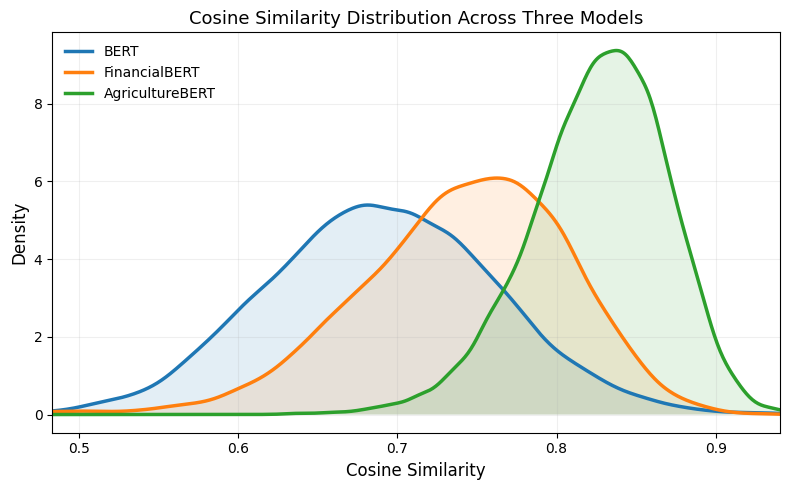

In [14]:
# ==============================
# 5. Improved Paper-style Plot
# KDE only, cleaner visualization
# ==============================

MODEL_DISPLAY_NAMES = {
    "google-bert/bert-base-uncased": "BERT",
    "ahmedrachid/FinancialBERT": "FinancialBERT",
    "recobo/agriculture-bert-uncased": "AgricultureBERT"
}

plt.figure(figsize=(8, 5))

# Automatically zoom into the meaningful distribution range
all_scores = np.concatenate(list(cosine_results.values()))

x_min = max(0, np.percentile(all_scores, 0.5) - 0.03)
x_max = min(1, np.percentile(all_scores, 99.5) + 0.03)

x_grid = np.linspace(x_min, x_max, 500)

for model_name, scores in cosine_results.items():
    display_name = MODEL_DISPLAY_NAMES.get(model_name, model_name)

    kde = gaussian_kde(scores)
    y_values = kde(x_grid)

    plt.plot(
        x_grid,
        y_values,
        linewidth=2.5,
        label=display_name
    )

    plt.fill_between(
        x_grid,
        y_values,
        alpha=0.12
    )

plt.xlabel("Cosine Similarity", fontsize=12)
plt.ylabel("Density", fontsize=12)
plt.title("Cosine Similarity Distribution Across Three Models", fontsize=13)

plt.xlim(x_min, x_max)

plt.legend(
    frameon=False,
    fontsize=10
)

plt.grid(True, alpha=0.2)
plt.tight_layout()

plt.savefig(
    "cosine_similarity_distribution_clean.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [17]:
# ==============================
# Within-label vs Between-label Cosine Similarity Distribution
# For the same dataset and the same selected models
# ==============================

import gc
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gaussian_kde, skew

# 1. Select models
SELECTED_MODELS = [
    "google-bert/bert-base-uncased",
    "ahmedrachid/FinancialBERT",
    "recobo/agriculture-bert-uncased"
]

# 2. Short display names
MODEL_DISPLAY_NAMES = {
    "google-bert/bert-base-uncased": "BERT",
    "ahmedrachid/FinancialBERT": "FinancialBERT",
    "recobo/agriculture-bert-uncased": "AgricultureBERT"
}

# 3. Sample data
sampled_df = sample_from_length_groups(
    df,
    sample_size=SAMPLE_SIZE,
    num_quantiles=100,
    random_seed=RANDOM_SEED
)

texts = sampled_df["clean_sentence"].tolist()
labels = sampled_df[LABEL_COL].values

print("Sample size:", len(texts))
print("Label distribution in sampled data:")
print(pd.Series(labels).value_counts().sort_index())


# 4. Function: calculate overlap area between two distributions
def calculate_distribution_overlap(scores_a, scores_b, bins=50, value_range=(0, 1)):
    """
    Calculate histogram-based overlap area between two distributions.
    The value range is 0 to 1.
    
    overlap close to 1: two distributions are highly overlapped
    overlap close to 0: two distributions are well separated
    """
    hist_a, bin_edges = np.histogram(
        scores_a,
        bins=bins,
        range=value_range,
        density=True
    )

    hist_b, _ = np.histogram(
        scores_b,
        bins=bins,
        range=value_range,
        density=True
    )

    bin_widths = np.diff(bin_edges)

    overlap = np.sum(np.minimum(hist_a, hist_b) * bin_widths)

    return overlap


# 5. Store results
within_between_results = {}
summary_rows = []


# 6. Compute within-label and between-label distributions
for model_name in SELECTED_MODELS:
    print("\n==============================")
    print("Running model:", model_name)
    print("==============================")

    embeddings = compute_embeddings(
        texts,
        model_name=model_name,
        batch_size=BATCH_SIZE,
        max_token=MAX_TOKEN
    )

    # Within-label cosine similarity
    within_scores, scores_by_label = calculate_within_label_cosine_distribution(
        embeddings,
        labels,
        return_by_label=True
    )

    # Between-label cosine similarity
    between_scores, scores_by_label_pair = calculate_between_label_cosine_distribution(
        embeddings,
        labels,
        return_by_label_pair=True
    )

    # Remove nan values
    within_scores = within_scores[np.isfinite(within_scores)]
    between_scores = between_scores[np.isfinite(between_scores)]

    # For plotting in 0-1 range, check whether negative values exist
    within_negative_ratio = np.mean(within_scores < 0)
    between_negative_ratio = np.mean(between_scores < 0)

    # Distribution overlap in 0-1 range
    overlap_score = calculate_distribution_overlap(
        within_scores,
        between_scores,
        bins=50,
        value_range=(0, 1)
    )

    mean_gap = np.mean(within_scores) - np.mean(between_scores)

    within_between_results[model_name] = {
        "within_scores": within_scores,
        "between_scores": between_scores,
        "scores_by_label": scores_by_label,
        "scores_by_label_pair": scores_by_label_pair,
        "overlap_score": overlap_score,
        "mean_gap": mean_gap
    }

    summary_rows.append({
        "model": MODEL_DISPLAY_NAMES.get(model_name, model_name),
        "within_mean": np.mean(within_scores),
        "between_mean": np.mean(between_scores),
        "mean_gap": mean_gap,
        "within_std": np.std(within_scores),
        "between_std": np.std(between_scores),
        "within_skewness": skew(within_scores),
        "between_skewness": skew(between_scores),
        "overlap_score": overlap_score,
        "within_negative_ratio": within_negative_ratio,
        "between_negative_ratio": between_negative_ratio
    })

    print("Within-label mean:", np.mean(within_scores))
    print("Between-label mean:", np.mean(between_scores))
    print("Mean gap:", mean_gap)
    print("Overlap score:", overlap_score)
    print("Within negative ratio:", within_negative_ratio)
    print("Between negative ratio:", between_negative_ratio)

    # clean GPU / RAM
    del embeddings
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()


# 7. Convert summary to DataFrame
summary_df = pd.DataFrame(summary_rows)

print("\nSummary:")
print(summary_df)

summary_df.to_csv("within_between_cosine_summary.csv", index=False)

Actual Sample Size: 200
Minimum Token Count: 5
Average Token Count: 21.645
Maximum Token Count: 49
Sample size: 200
Label distribution in sampled data:
0     31
1    123
2     46
Name: count, dtype: int64

Running model: google-bert/bert-base-uncased


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: google-bert/bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Label 0: 31 samples, 465 pairs
Label 1: 123 samples, 7503 pairs
Label 2: 46 samples, 1035 pairs
Total between-label pairs: 10897
Label 1 vs Label 2: 5658 pairs
Label 0 vs Label 1: 3813 pairs
Label 0 vs Label 2: 1426 pairs
Within-label mean: 0.6893733646966849
Between-label mean: 0.6896084244807861
Mean gap: -0.0002350597841012103
Overlap score: 0.9835521468372309
Within negative ratio: 0.0
Between negative ratio: 0.0

Running model: ahmedrachid/FinancialBERT


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: ahmedrachid/FinancialBERT
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstr

Label 0: 31 samples, 465 pairs
Label 1: 123 samples, 7503 pairs
Label 2: 46 samples, 1035 pairs
Total between-label pairs: 10897
Label 1 vs Label 2: 5658 pairs
Label 0 vs Label 1: 3813 pairs
Label 0 vs Label 2: 1426 pairs
Within-label mean: 0.7447872210261319
Between-label mean: 0.7360701570874498
Mean gap: 0.008717063938682101
Overlap score: 0.9336815027376955
Within negative ratio: 0.0
Between negative ratio: 0.0

Running model: recobo/agriculture-bert-uncased


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

BertModel LOAD REPORT from: recobo/agriculture-bert-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
bert.embeddings.position_ids               | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
pooler.dense.bias                          | MISSING    | 
pooler.dense.weight                        | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your d

Label 0: 31 samples, 465 pairs
Label 1: 123 samples, 7503 pairs
Label 2: 46 samples, 1035 pairs
Total between-label pairs: 10897
Label 1 vs Label 2: 5658 pairs
Label 0 vs Label 1: 3813 pairs
Label 0 vs Label 2: 1426 pairs
Within-label mean: 0.8268672400324342
Between-label mean: 0.8250142593629712
Mean gap: 0.0018529806694629336
Overlap score: 0.9669740769676655
Within negative ratio: 0.0
Between negative ratio: 0.0

Summary:
             model  within_mean  between_mean  mean_gap  within_std  \
0             BERT     0.689373      0.689608 -0.000235    0.073228   
1    FinancialBERT     0.744787      0.736070  0.008717    0.069563   
2  AgricultureBERT     0.826867      0.825014  0.001853    0.044066   

   between_std  within_skewness  between_skewness  overlap_score  \
0     0.072297         0.038415         -0.011327       0.983552   
1     0.066901        -0.913058         -0.612782       0.933682   
2     0.042803        -0.530247         -0.420184       0.966974   

   within_ne

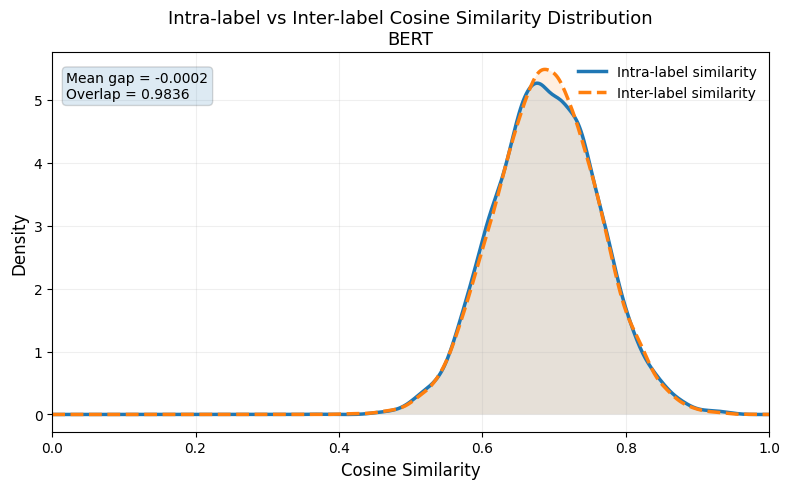

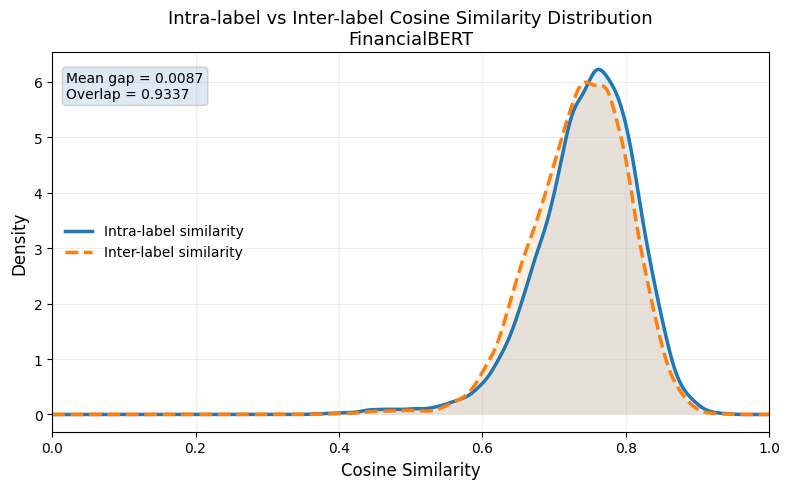

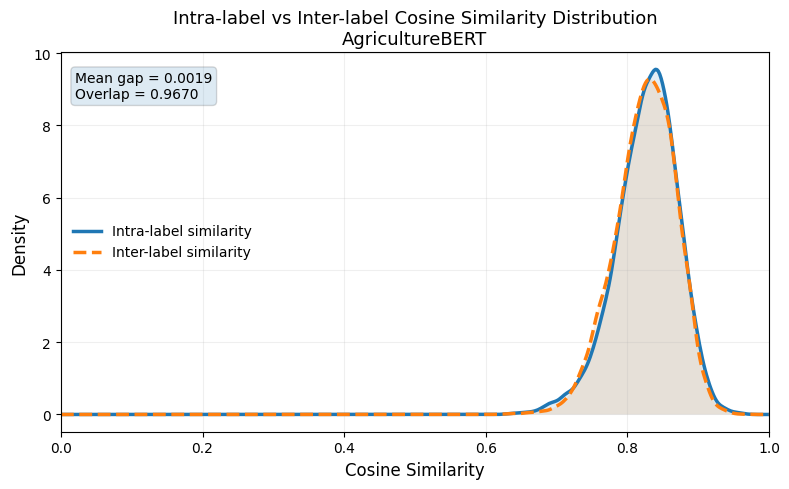

In [18]:
# ==============================
# Plot within-label vs between-label distribution
# One figure for each model
# ==============================

for model_name, result in within_between_results.items():
    display_name = MODEL_DISPLAY_NAMES.get(model_name, model_name)

    within_scores = result["within_scores"]
    between_scores = result["between_scores"]

    overlap_score = result["overlap_score"]
    mean_gap = result["mean_gap"]

    plt.figure(figsize=(8, 5))

    x_grid = np.linspace(0, 1, 500)

    # KDE for within-label
    kde_within = gaussian_kde(within_scores)
    y_within = kde_within(x_grid)

    plt.plot(
        x_grid,
        y_within,
        linewidth=2.5,
        label="Intra-label similarity"
    )

    plt.fill_between(
        x_grid,
        y_within,
        alpha=0.12
    )

    # KDE for between-label
    kde_between = gaussian_kde(between_scores)
    y_between = kde_between(x_grid)

    plt.plot(
        x_grid,
        y_between,
        linewidth=2.5,
        linestyle="--",
        label="Inter-label similarity"
    )

    plt.fill_between(
        x_grid,
        y_between,
        alpha=0.12
    )

    plt.xlabel("Cosine Similarity", fontsize=12)
    plt.ylabel("Density", fontsize=12)

    plt.title(
        f"Intra-label vs Inter-label Cosine Similarity Distribution\n{display_name}",
        fontsize=13
    )

    plt.xlim(0, 1)

    plt.text(
        0.02,
        0.95,
        f"Mean gap = {mean_gap:.4f}\nOverlap = {overlap_score:.4f}",
        transform=plt.gca().transAxes,
        fontsize=10,
        verticalalignment="top",
        bbox=dict(boxstyle="round", alpha=0.15)
    )

    plt.legend(frameon=False, fontsize=10)
    plt.grid(True, alpha=0.2)
    plt.tight_layout()

    safe_name = display_name.replace("/", "_").replace(" ", "_")

    plt.savefig(
        f"within_between_cosine_distribution_{safe_name}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

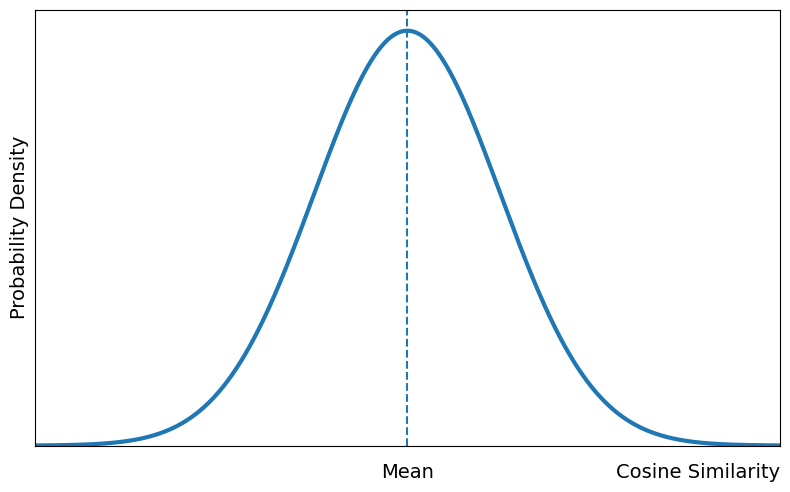

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Gaussian parameters
mean = 0.0       # 中心位置
std = 0.25       # 曲线宽度

# Cosine similarity range
x = np.linspace(-1, 1, 1000)
pdf = norm.pdf(x, loc=mean, scale=std)

fig, ax = plt.subplots(figsize=(8, 5))

# PDF curve
ax.plot(x, pdf, linewidth=3)

# Mean line
ax.axvline(
    mean,
    linestyle="--",
    linewidth=1.5
)

# Mean label
ax.text(
    mean,
    -0.04,
    "Mean",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14
)

# Put x-axis label on the right
ax.text(
    1.0,
    -0.04,
    "Cosine Similarity",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=14
)

# Y-axis label
ax.set_ylabel("Probability Density", fontsize=14)

# Remove numerical values
ax.set_xticks([])
ax.set_yticks([])

ax.set_xlim(-1, 1)
ax.set_ylim(bottom=0)

plt.tight_layout()
plt.show()

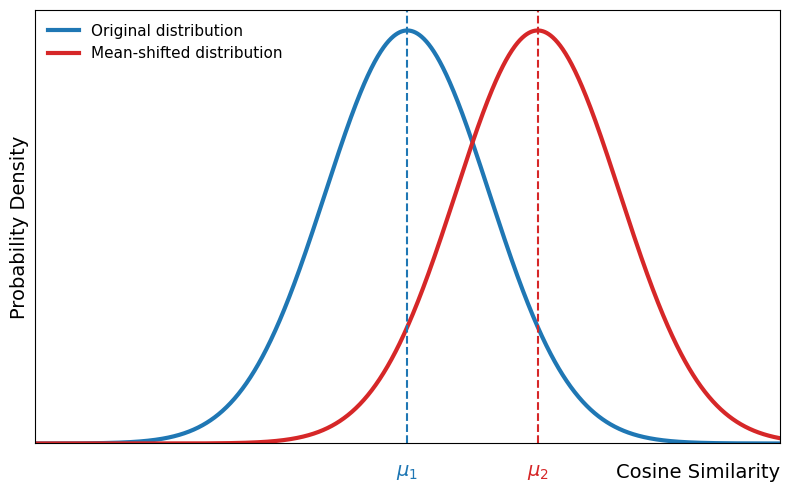

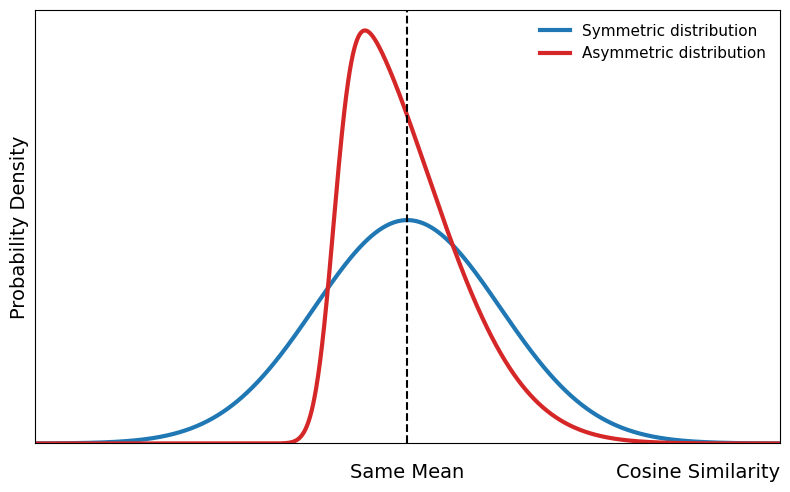

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, skewnorm


# Shared plotting range
x = np.linspace(-1, 1, 1500)


# ============================================================
# Figure 1: Different means, same symmetric distribution shape
# ============================================================

blue_mean = 0.0
red_mean = 0.35
std = 0.22

blue_pdf = norm.pdf(x, loc=blue_mean, scale=std)
red_pdf = norm.pdf(x, loc=red_mean, scale=std)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    x,
    blue_pdf,
    linewidth=3,
    color="tab:blue",
    label="Original distribution"
)

ax.plot(
    x,
    red_pdf,
    linewidth=3,
    color="tab:red",
    label="Mean-shifted distribution"
)

# Mean lines
ax.axvline(
    blue_mean,
    linestyle="--",
    linewidth=1.5,
    color="tab:blue"
)

ax.axvline(
    red_mean,
    linestyle="--",
    linewidth=1.5,
    color="tab:red"
)

# Mean labels
ax.text(
    blue_mean,
    -0.045,
    r"$\mu_1$",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14,
    color="tab:blue"
)

ax.text(
    red_mean,
    -0.045,
    r"$\mu_2$",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14,
    color="tab:red"
)

# Axis labels
ax.set_ylabel("Probability Density", fontsize=14)

ax.text(
    1.0,
    -0.045,
    "Cosine Similarity",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=14
)

# Remove numerical tick labels
ax.set_xticks([])
ax.set_yticks([])

ax.set_xlim(-1, 1)
ax.set_ylim(bottom=0)

ax.legend(frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig(
    "different_means.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ============================================================
# Figure 2: Same mean, different asymmetry
# ============================================================

common_mean = 0.0

# Symmetric Gaussian distribution
normal_std = 0.25
symmetric_pdf = norm.pdf(
    x,
    loc=common_mean,
    scale=normal_std
)

# Asymmetric skew-normal distribution
shape = 6.0
skew_scale = 0.25

# Adjust loc so the skew-normal distribution has mean = common_mean
delta = shape / np.sqrt(1 + shape**2)

skew_loc = (
    common_mean
    - skew_scale * delta * np.sqrt(2 / np.pi)
)

asymmetric_pdf = skewnorm.pdf(
    x,
    a=shape,
    loc=skew_loc,
    scale=skew_scale
)

fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    x,
    symmetric_pdf,
    linewidth=3,
    color="tab:blue",
    label="Symmetric distribution"
)

ax.plot(
    x,
    asymmetric_pdf,
    linewidth=3,
    color="tab:red",
    label="Asymmetric distribution"
)

# Both distributions have the same mean
ax.axvline(
    common_mean,
    linestyle="--",
    linewidth=1.5,
    color="black"
)

ax.text(
    common_mean,
    -0.045,
    "Same Mean",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14
)

# Axis labels
ax.set_ylabel("Probability Density", fontsize=14)

ax.text(
    1.0,
    -0.045,
    "Cosine Similarity",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=14
)

# Remove numerical tick labels
ax.set_xticks([])
ax.set_yticks([])

ax.set_xlim(-1, 1)
ax.set_ylim(bottom=0)

ax.legend(frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig(
    "same_mean_different_asymmetry.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

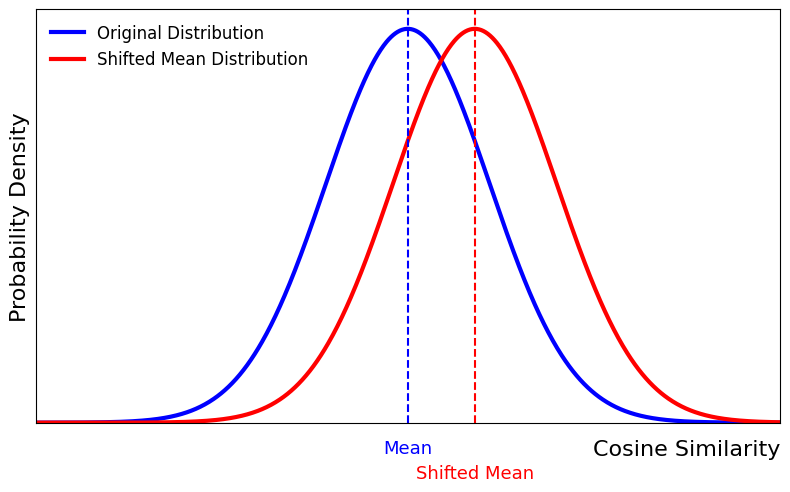

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# x range
x = np.linspace(-1, 1, 1000)

# Blue distribution: original Gaussian
mean_blue = 0.0
std_blue = 0.22
pdf_blue = norm.pdf(x, loc=mean_blue, scale=std_blue)

# Red distribution: shifted mean
mean_red = 0.18
std_red = 0.22
pdf_red = norm.pdf(x, loc=mean_red, scale=std_red)

# Plot
plt.figure(figsize=(8, 5))

plt.plot(x, pdf_blue, color='blue', linewidth=3, label='Original Distribution')
plt.plot(x, pdf_red, color='red', linewidth=3, label='Shifted Mean Distribution')

# Mean lines
plt.axvline(mean_blue, color='blue', linestyle='--', linewidth=1.5)
plt.axvline(mean_red, color='red', linestyle='--', linewidth=1.5)

# Mean labels
plt.text(mean_blue, -0.04, "Mean", color='blue',
         transform=plt.gca().get_xaxis_transform(),
         ha='center', va='top', fontsize=13)

plt.text(mean_red, -0.10, "Shifted Mean", color='red',
         transform=plt.gca().get_xaxis_transform(),
         ha='center', va='top', fontsize=13)

# Axis labels
plt.ylabel("Probability Density", fontsize=16)
plt.text(1.0, -0.04, "Cosine Similarity",
         transform=plt.gca().transAxes,
         ha='right', va='top', fontsize=16)

# Remove tick values
plt.xticks([])
plt.yticks([])

plt.xlim(-1, 1)
plt.ylim(bottom=0)
plt.legend(frameon=False, fontsize=12)
plt.tight_layout()
plt.show()

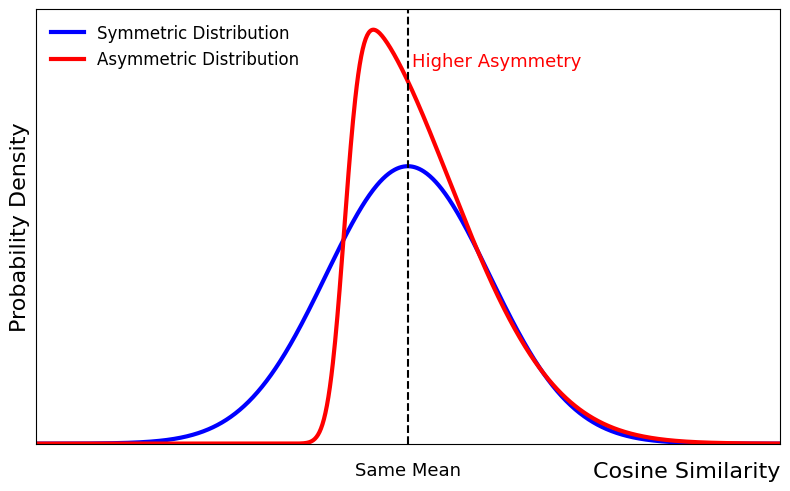

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, skewnorm

# x range
x = np.linspace(-1, 1, 1000)

# Blue distribution: symmetric Gaussian
mean_blue = 0.0
std_blue = 0.22
pdf_blue = norm.pdf(x, loc=mean_blue, scale=std_blue)

# Red distribution: skewed distribution with approximately same mean
# a controls skewness: a > 0 right-skew, a < 0 left-skew
a = 8
loc_red = -0.17   # adjusted so the visual center is close to the blue mean
scale_red = 0.28
pdf_red = skewnorm.pdf(x, a=a, loc=loc_red, scale=scale_red)

# Plot
plt.figure(figsize=(8, 5))

plt.plot(x, pdf_blue, color='blue', linewidth=3, label='Symmetric Distribution')
plt.plot(x, pdf_red, color='red', linewidth=3, label='Asymmetric Distribution')

# Shared reference mean line
plt.axvline(0.0, color='black', linestyle='--', linewidth=1.5)

# Mean label
plt.text(0.0, -0.04, "Same Mean", color='black',
         transform=plt.gca().get_xaxis_transform(),
         ha='center', va='top', fontsize=13)

# Asymmetry annotation
plt.text(0.62, 0.88, "Higher Asymmetry", color='red',
         transform=plt.gca().transAxes,
         ha='center', va='center', fontsize=13)

# Axis labels
plt.ylabel("Probability Density", fontsize=16)
plt.text(1.0, -0.04, "Cosine Similarity",
         transform=plt.gca().transAxes,
         ha='right', va='top', fontsize=16)

# Remove tick values
plt.xticks([])
plt.yticks([])

plt.xlim(-1, 1)
plt.ylim(bottom=0)
plt.legend(frameon=False, fontsize=12)
plt.tight_layout()
plt.show()

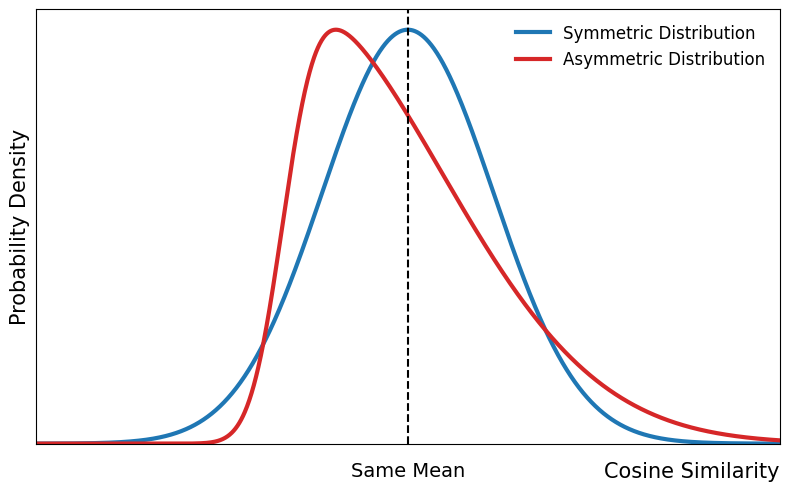

Blue mean: 0.000000
Red mean:  0.000000
Blue peak height: 1.734528
Red peak height:  1.734526


In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm, skewnorm
from scipy.optimize import minimize_scalar

# -----------------------------
# Shared settings
# -----------------------------
shared_mean = 0.0

# Blue normal distribution
blue_std = 0.23

# Red skew-normal distribution
# Positive value: right-skewed
# Negative value: left-skewed
shape_a = 6

# -----------------------------
# Blue distribution
# -----------------------------
blue_peak_height = norm.pdf(
    shared_mean,
    loc=shared_mean,
    scale=blue_std
)

# -----------------------------
# Find the maximum height of a
# standard skew-normal PDF
# -----------------------------
result = minimize_scalar(
    lambda z: -skewnorm.pdf(z, a=shape_a),
    bounds=(-5, 5),
    method="bounded"
)

standard_skew_peak = -result.fun

# Choose the red scale so that its peak height
# is exactly the same as the blue peak height
red_scale = standard_skew_peak / blue_peak_height

# Choose red location so that its mean is shared_mean
delta = shape_a / np.sqrt(1 + shape_a**2)

red_location = (
    shared_mean
    - red_scale * delta * np.sqrt(2 / np.pi)
)

# -----------------------------
# Generate probability densities
# -----------------------------
x = np.linspace(-1, 1, 2000)

blue_pdf = norm.pdf(
    x,
    loc=shared_mean,
    scale=blue_std
)

red_pdf = skewnorm.pdf(
    x,
    a=shape_a,
    loc=red_location,
    scale=red_scale
)

# -----------------------------
# Plot
# -----------------------------
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    x,
    blue_pdf,
    linewidth=3,
    color="tab:blue",
    label="Symmetric Distribution"
)

ax.plot(
    x,
    red_pdf,
    linewidth=3,
    color="tab:red",
    label="Asymmetric Distribution"
)

# Shared mean
ax.axvline(
    shared_mean,
    linestyle="--",
    linewidth=1.5,
    color="black"
)

ax.text(
    shared_mean,
    -0.04,
    "Same Mean",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top",
    fontsize=14
)

# Axis labels
ax.set_ylabel(
    "Probability Density",
    fontsize=15
)

ax.text(
    1.0,
    -0.04,
    "Cosine Similarity",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=15
)

# Remove numerical tick labels
ax.set_xticks([])
ax.set_yticks([])

ax.set_xlim(-1, 1)
ax.set_ylim(
    bottom=0,
    top=blue_peak_height * 1.05
)

ax.legend(
    frameon=False,
    fontsize=12
)

plt.tight_layout()
plt.show()

# Verification
red_mean = skewnorm.mean(
    a=shape_a,
    loc=red_location,
    scale=red_scale
)

print(f"Blue mean: {shared_mean:.6f}")
print(f"Red mean:  {red_mean:.6f}")
print(f"Blue peak height: {blue_pdf.max():.6f}")
print(f"Red peak height:  {red_pdf.max():.6f}")

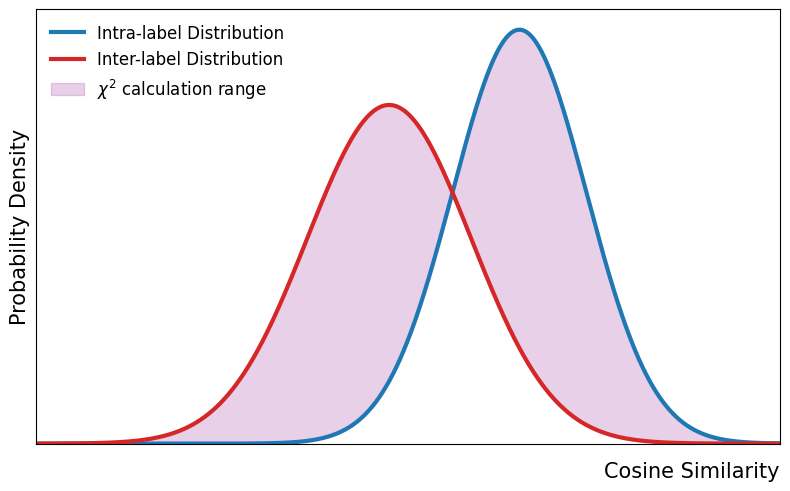

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# x range
x = np.linspace(-1, 1, 1500)

# Example distributions
# Intra-label distribution
intra_mean = 0.30
intra_std = 0.18
intra_pdf = norm.pdf(x, loc=intra_mean, scale=intra_std)

# Inter-label distribution
inter_mean = -0.05
inter_std = 0.22
inter_pdf = norm.pdf(x, loc=inter_mean, scale=inter_std)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(x, intra_pdf, color="tab:blue", linewidth=3, label="Intra-label Distribution")
ax.plot(x, inter_pdf, color="tab:red", linewidth=3, label="Inter-label Distribution")

# Show chi-square calculation range
ax.fill_between(
    x,
    intra_pdf,
    inter_pdf,
    color="purple",
    alpha=0.18,
    label=r"$\chi^2$ calculation range"
)

# Axis labels
ax.set_ylabel("Probability Density", fontsize=15)
ax.text(
    1.0,
    -0.04,
    "Cosine Similarity",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=15
)

# Remove numerical ticks
ax.set_xticks([])
ax.set_yticks([])

ax.set_xlim(-1, 1)
ax.set_ylim(bottom=0)

ax.legend(frameon=False, fontsize=12)
plt.tight_layout()
plt.show()